达到最大迭代次数50次后停止


C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAPH-635F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 22833 (\N{CJK UNIFIED IDEOGRAPH-5931}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\12518\AppData\Local\Temp\ipykernel_25096\2264988348.py:115: UserWarning: Glyph 38

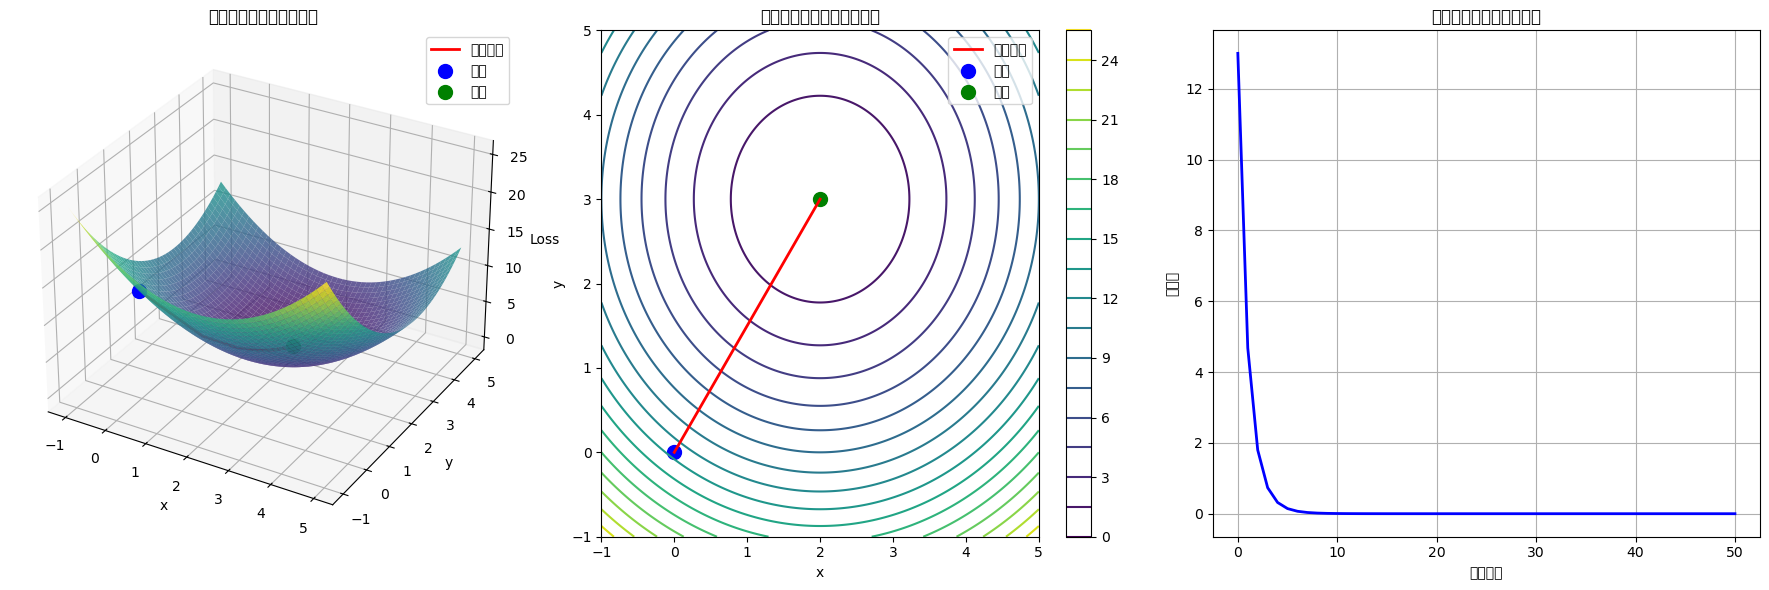

初始点: (0, 0), 初始损失: 13.000000
最终点: (1.999549, 2.999323), 最终损失: 0.000001
迭代次数: 50


In [8]:
#梯度下降问题
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def loss_function(x, y):
    """
    定义损失函数: f(x,y) = (x-2)^2 + (y-3)^2
    最小值在点(2,3)处取得
    """
    return (x - 2)**2 + (y - 3)**2

def gradient(x, y):
    """
    计算损失函数的梯度
    返回: (grad_x, grad_y)
    """
    grad_x = 2 * (x - 2)
    grad_y = 2 * (y - 3)
    return grad_x, grad_y

def gradient_descent(initial_point, learning_rate=0.1, max_iterations=100, 
                    tolerance=1e-6, decay_rate=0.95):
    """
    优化后的梯度下降算法实现
    
    参数:
        initial_point: 初始点坐标 (x0, y0)
        learning_rate: 初始学习率 (默认0.1)
        max_iterations: 最大迭代次数 (默认100)
        tolerance: 收敛阈值 (默认1e-6)
        decay_rate: 学习率衰减率 (默认0.95)
        
    返回:
        trajectory: 优化路径上的所有点
        losses: 每次迭代的损失值
    """
    x, y = initial_point
    trajectory = [(x, y)]
    losses = [loss_function(x, y)]
    
    for i in range(max_iterations):
        grad_x, grad_y = gradient(x, y)
        
        # 更新参数
        x -= learning_rate * grad_x
        y -= learning_rate * grad_y
        
        # 记录轨迹和损失
        trajectory.append((x, y))
        current_loss = loss_function(x, y)
        losses.append(current_loss)
        
        # 检查收敛条件
        if np.linalg.norm([grad_x, grad_y]) < tolerance:
            print(f"在{i+1}次迭代后收敛")
            break
            
        # 学习率衰减
        learning_rate *= decay_rate
    else:
        print(f"达到最大迭代次数{max_iterations}次后停止")
    
    return np.array(trajectory), np.array(losses)

# 参数设置
initial_point = (0, 0)
learning_rate = 0.2
max_iterations = 50

# 运行梯度下降
trajectory, losses = gradient_descent(initial_point, learning_rate, max_iterations)

# 准备可视化数据
x_vals = np.linspace(-1, 5, 400)
y_vals = np.linspace(-1, 5, 400)
X, Y = np.meshgrid(x_vals, y_vals)
Z = loss_function(X, Y)

# 创建可视化图形
plt.figure(figsize=(18, 6))

# 1. 损失函数曲面图
ax1 = plt.subplot(131, projection='3d')
ax1.plot_surface(X, Y, Z, cmap='viridis', alpha=0.8)
ax1.plot(trajectory[:, 0], trajectory[:, 1], losses, 'r-', linewidth=2, label='优化路径')
ax1.scatter(trajectory[0, 0], trajectory[0, 1], losses[0], color='blue', s=100, label='起点')
ax1.scatter(trajectory[-1, 0], trajectory[-1, 1], losses[-1], color='green', s=100, label='终点')
ax1.set_title('损失函数曲面与优化路径')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('Loss')
ax1.legend()

# 2. 等高线图
ax2 = plt.subplot(132)
contour = ax2.contour(X, Y, Z, levels=20, cmap='viridis')
plt.colorbar(contour, ax=ax2)
ax2.plot(trajectory[:, 0], trajectory[:, 1], 'r-', linewidth=2, label='优化路径')
ax2.scatter(trajectory[0, 0], trajectory[0, 1], color='blue', s=100, label='起点')
ax2.scatter(trajectory[-1, 0], trajectory[-1, 1], color='green', s=100, label='终点')
ax2.set_title('损失函数等高线与优化路径')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.legend()

# 3. 损失值变化曲线
ax3 = plt.subplot(133)
ax3.plot(losses, 'b-', linewidth=2)
ax3.set_title('损失值随迭代次数的变化')
ax3.set_xlabel('迭代次数')
ax3.set_ylabel('损失值')
ax3.grid(True)

plt.tight_layout()
plt.show()

# 打印最终结果
print(f"初始点: ({initial_point[0]}, {initial_point[1]}), 初始损失: {losses[0]:.6f}")
print(f"最终点: ({trajectory[-1, 0]:.6f}, {trajectory[-1, 1]:.6f}), 最终损失: {losses[-1]:.6f}")
print(f"迭代次数: {len(trajectory)-1}")

C:\Users\12518\anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


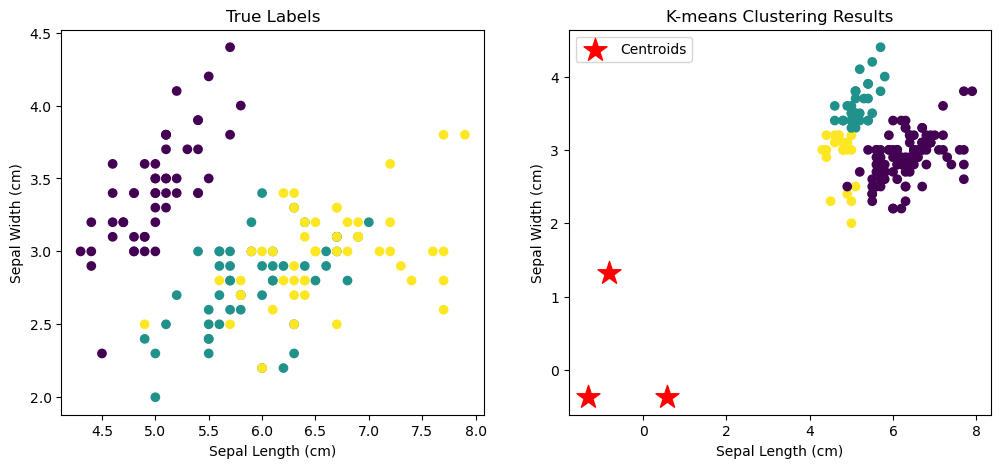

Clustering Accuracy: 0.00

Composition of Cluster 0:
  setosa: 0
  versicolor: 46
  virginica: 50

Composition of Cluster 1:
  setosa: 33
  versicolor: 0
  virginica: 0

Composition of Cluster 2:
  setosa: 17
  versicolor: 4
  virginica: 0


In [4]:
#鸢尾花聚类
from sklearn import datasets

# 加载数据集
iris = datasets.load_iris()
X = iris.data
y = iris.target

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)

y_kmeans = kmeans.predict(X_scaled)

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# 原始数据的真实类别
plt.subplot(121)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis')
plt.title('True Labels')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')

# K-means聚类的结果
plt.subplot(122)
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
            s=300, c='red', marker='*', label='Centroids')
plt.title('K-means Clustering Results')
plt.xlabel('Sepal Length (cm)')
plt.ylabel('Sepal Width (cm)')
plt.legend()
plt.show()

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y, y_kmeans)
print(f"Clustering Accuracy: {accuracy:.2f}")

for i in range(3):
    cluster = np.where(y_kmeans == i)[0]
    print(f"\nComposition of Cluster {i}:")
    for iris_type in range(3):
        count = np.sum(y[cluster] == iris_type)
        print(f"  {iris.target_names[iris_type]}: {count}")

In [6]:
#鸢尾花降维
from sklearn import datasets

# 加载数据集
iris = datasets.load_iris()
X = iris.data
y = iris.target

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

from sklearn.decomposition import PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance_ratio = pca.explained_variance_ratio_
print(f"Explained Variance Ratio: {explained_variance_ratio}")

print("主成分的特征向量:")
for i, component in enumerate(pca.components_):
    print(f"PC{i+1}: {component}")

print("\n原始特征与主成分的相关性:")
for i, component in enumerate(pca.components_):
    correlations = component * np.sqrt(pca.explained_variance_[i])
    print(f"PC{i+1}:")
    for j, corr in enumerate(correlations):
        print(f"  {iris.feature_names[j]}: {corr:.3f}")

Explained Variance Ratio: [0.72962445 0.22850762 0.03668922 0.00517871]
主成分的特征向量:
PC1: [ 0.52106591 -0.26934744  0.5804131   0.56485654]
PC2: [0.37741762 0.92329566 0.02449161 0.06694199]
PC3: [ 0.71956635 -0.24438178 -0.14212637 -0.63427274]
PC4: [-0.26128628  0.12350962  0.80144925 -0.52359713]

原始特征与主成分的相关性:
PC1:
  sepal length (cm): 0.893
  sepal width (cm): -0.462
  petal length (cm): 0.995
  petal width (cm): 0.968
PC2:
  sepal length (cm): 0.362
  sepal width (cm): 0.886
  petal length (cm): 0.023
  petal width (cm): 0.064
PC3:
  sepal length (cm): 0.277
  sepal width (cm): -0.094
  petal length (cm): -0.055
  petal width (cm): -0.244
PC4:
  sepal length (cm): -0.038
  sepal width (cm): 0.018
  petal length (cm): 0.116
  petal width (cm): -0.076


In [10]:
#装箱子
def bin_packing(items, bin_capacity):
    """
    装箱子问题 - 首次适应递减算法(FFD)
    参数:
        items: 物品重量列表
        bin_capacity: 每个箱子的容量
    返回:
        bins: 装箱方案
        bin_count: 使用的箱子数量
    """
    # 按重量降序排序
    items_sorted = sorted(items, reverse=True)
    
    bins = []
    for item in items_sorted:
        # 尝试将物品放入已有箱子
        placed = False
        for bin in bins:
            if sum(bin) + item <= bin_capacity:
                bin.append(item)
                placed = True
                break
        # 如果没有合适的箱子，开一个新箱子
        if not placed:
            bins.append([item])
    
    return bins, len(bins)

# 示例使用
items = [4, 8, 1, 4, 2, 1, 5, 3, 7]
bin_capacity = 10
bins, num_bins = bin_packing(items, bin_capacity)

print(f"物品列表: {items}")
print(f"箱子容量: {bin_capacity}")
print(f"需要的箱子数量: {num_bins}")
print("装箱方案:")
for i, bin in enumerate(bins, 1):
    print(f"箱子{i}: {bin} (总重量: {sum(bin)})")

物品列表: [4, 8, 1, 4, 2, 1, 5, 3, 7]
箱子容量: 10
需要的箱子数量: 4
装箱方案:
箱子1: [8, 2] (总重量: 10)
箱子2: [7, 3] (总重量: 10)
箱子3: [5, 4, 1] (总重量: 10)
箱子4: [4, 1] (总重量: 5)


In [12]:
#斐波那契
def fibonacci_dp(n):
    """
    使用动态规划计算斐波那契数列
    参数:
        n: 要计算的斐波那契数列项数
    返回:
        第n项斐波那契数
    """
    if n <= 1:
        return n
    
    # 初始化DP表
    dp = [0] * (n + 1)
    dp[1] = 1
    
    # 填充DP表
    for i in range(2, n + 1):
        dp[i] = dp[i - 1] + dp[i - 2]
    
    return dp[n]

# 示例使用
n = 10
print(f"斐波那契数列前{n}项:")
for i in range(n + 1):
    print(f"F({i}) = {fibonacci_dp(i)}")

斐波那契数列前10项:
F(0) = 0
F(1) = 1
F(2) = 1
F(3) = 2
F(4) = 3
F(5) = 5
F(6) = 8
F(7) = 13
F(8) = 21
F(9) = 34
F(10) = 55


In [14]:
#八数码
from collections import deque
import copy

def solve_8_puzzle(start, goal):
    """
    使用BFS解决八数码问题
    参数:
        start: 初始状态(3x3列表)
        goal: 目标状态(3x3列表)
    返回:
        解决步骤或无法解决的消息
    """
    # 可能的移动方向
    directions = [(0, 1), (1, 0), (0, -1), (-1, 0)]
    
    # 队列存储状态和路径
    queue = deque()
    queue.append((start, []))
    visited = set()
    
    # 将状态转换为字符串以便哈希
    def state_to_str(state):
        return ''.join(''.join(str(cell) for cell in row) for row in state)
    
    while queue:
        current_state, path = queue.popleft()
        
        # 检查是否达到目标状态
        if current_state == goal:
            return path + [current_state]
        
        # 找到空格(0)的位置
        for i in range(3):
            for j in range(3):
                if current_state[i][j] == 0:
                    x, y = i, j
                    break
        
        # 尝试所有可能的移动
        for dx, dy in directions:
            nx, ny = x + dx, y + dy
            if 0 <= nx < 3 and 0 <= ny < 3:
                # 创建新状态
                new_state = copy.deepcopy(current_state)
                new_state[x][y], new_state[nx][ny] = new_state[nx][ny], new_state[x][y]
                
                # 检查是否已访问过
                state_str = state_to_str(new_state)
                if state_str not in visited:
                    visited.add(state_str)
                    queue.append((new_state, path + [current_state]))
    
    return "无法找到解决方案"

# 示例使用
start = [
    [1, 2, 3],
    [4, 0, 6],
    [7, 5, 8]
]
goal = [
    [1, 2, 3],
    [4, 5, 6],
    [7, 8, 0]
]

solution = solve_8_puzzle(start, goal)
if isinstance(solution, list):
    print("找到解决方案，步骤如下:")
    for i, state in enumerate(solution):
        print(f"步骤 {i}:")
        for row in state:
            print(row)
        print()
else:
    print(solution)

找到解决方案，步骤如下:
步骤 0:
[1, 2, 3]
[4, 0, 6]
[7, 5, 8]

步骤 1:
[1, 2, 3]
[4, 5, 6]
[7, 0, 8]

步骤 2:
[1, 2, 3]
[4, 5, 6]
[7, 8, 0]



In [16]:
#皇后
def solve_n_queens(n):
    """
    使用回溯法解决N皇后问题
    参数:
        n: 棋盘大小
    返回:
        所有解法的列表
    """
    def backtrack(row, cols, diag1, diag2, board, res):
        if row == n:
            res.append([''.join(row) for row in board])
            return
        
        for col in range(n):
            d1 = row - col  # 主对角线
            d2 = row + col  # 副对角线
            
            if col not in cols and d1 not in diag1 and d2 not in diag2:
                # 放置皇后
                board[row][col] = 'Q'
                cols.add(col)
                diag1.add(d1)
                diag2.add(d2)
                
                # 递归下一行
                backtrack(row + 1, cols, diag1, diag2, board, res)
                
                # 回溯
                board[row][col] = '.'
                cols.remove(col)
                diag1.remove(d1)
                diag2.remove(d2)
    
    res = []
    board = [['.' for _ in range(n)] for _ in range(n)]
    backtrack(0, set(), set(), set(), board, res)
    return res

# 示例使用
n = 4
solutions = solve_n_queens(n)
print(f"{n}皇后问题共有 {len(solutions)} 种解法:")
for i, solution in enumerate(solutions, 1):
    print(f"解法 {i}:")
    for row in solution:
        print(row)
    print()

4皇后问题共有 2 种解法:
解法 1:
.Q..
...Q
Q...
..Q.

解法 2:
..Q.
Q...
...Q
.Q..



In [18]:
#心得
print("挺神奇的操作过程。代码看上去复杂，但是给出的答案却非常简洁。适合用在各个专业各个领域相应的问题中。")

挺神奇的操作过程。代码看上去复杂，但是给出的答案却非常简洁。适合用在各个专业各个领域相应的问题中。
